## Лабораторный практикум по курсу «Разговорный ИИ и большие языковые модели», Университет ИТМО, 2026
**Лабораторная работа №4. Гибридный поиск в векторной базе данных.**

**Задачи:**

1. Развернуть векторную базу (Qdrant).
2. Выбрать датасет ([mteb/fiqa](https://huggingface.co/datasets/mteb/fiqa)) и инициализировать коллекцию.
3. Векторизовать документы семантической (`multilingual-e5-small`) и лексической (`BM25`) моделями и загрузить их в коллекцию.
4. Настроить приемлемые скорость и качество поиска (параметры HNSW).
5. Замерить качество гибридного поиска с шагом альфа 0.1 (фьюжн и расчёт метрик -- вне БД).


## Подготовка

In [ ]:
!uv pip install -q "qdrant-client[fastembed]" sentence-transformers datasets matplotlib pandas

In [ ]:
import time, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from fastembed import SparseTextEmbedding
from qdrant_client import QdrantClient, models
from IPython.display import display
from tqdm import trange

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

SEMANTIC_MODEL = "intfloat/multilingual-e5-small"
LEXICAL_MODEL = "Qdrant/bm25"

QUERY_PREFIX, PASSAGE_PREFIX = "query: ", "passage: "
COLLECTION = "fiqa"

TOP_K = 100
BATCH = 1024
HNSW_EF = 128

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Векторная база

In [ ]:
USE_SERVER = False  # True -> настоящий сервер Qdrant, False -> :memory:

if USE_SERVER:
    !wget -q https://github.com/qdrant/qdrant/releases/download/v1.12.4/qdrant-x86_64-unknown-linux-gnu.tar.gz
    !tar -xzf qdrant-x86_64-unknown-linux-gnu.tar.gz
    import subprocess

    qdrant_proc = subprocess.Popen(
        ["./qdrant"], stdout=open("qdrant.log", "w"), stderr=subprocess.STDOUT
    )
    time.sleep(10)
    client = QdrantClient(url="http://localhost:6333", timeout=120)
else:
    client = QdrantClient(":memory:")
print(client.get_collections())

collections=[]


## 2. Датасет FiQA и инициализация коллекции

In [ ]:
corpus = load_dataset("mteb/fiqa", "corpus", split="corpus")
queries_ds = load_dataset("mteb/fiqa", "queries", split="queries")
qrels_ds = load_dataset("mteb/fiqa", "default", split="test")
print(len(corpus), len(queries_ds), len(qrels_ds))

doc_ids = corpus["_id"]
doc_texts = [
    ((t or "") + ". " + (b or "")).strip(". ")
    for t, b in zip(corpus["title"], corpus["text"])
]

qrels = {}
for r in qrels_ds:
    if r["score"] > 0:
        qrels.setdefault(r["query-id"], set()).add(r["corpus-id"])

q_text = dict(zip(queries_ds["_id"], queries_ds["text"]))
test_qids = [q for q in qrels if q in q_text]
print("test queries:", len(test_qids))

README.md:   0%|          | 0.00/9.58k [00:00<?, ?B/s]

corpus.jsonl: reconstructing file:   0%|          |  0.00B / 47.0MB            

corpus.jsonl: downloading bytes:           |  0.00B            

Generating corpus split:   0%|          | 0/57638 [00:00<?, ? examples/s]

queries.jsonl: reconstructing file:   0%|          |  0.00B /  600kB            

queries.jsonl: downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split:   0%|          | 0/14166 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/1238 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1706 [00:00<?, ? examples/s]

57638 6648 1706
test queries: 648


In [ ]:
SEMANTIC_MODEL = SentenceTransformer(SEMANTIC_MODEL, device=device)
bm25 = SparseTextEmbedding(LEXICAL_MODEL)
dim = SEMANTIC_MODEL.get_sentence_embedding_dimension()

if client.collection_exists(COLLECTION):
    client.delete_collection(COLLECTION)

client.create_collection(
    collection_name=COLLECTION,
    vectors_config={
        "dense": models.VectorParams(
            size=dim,
            distance=models.Distance.COSINE,
            hnsw_config=models.HnswConfigDiff(m=16, ef_construct=100),
        )
    },
    sparse_vectors_config={
        "bm25": models.SparseVectorParams(modifier=models.Modifier.IDF)
    },
)

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (8 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

/tmp/ipykernel_413/2736461884.py:3: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dim = dense_model.get_sentence_embedding_dimension()


True

## 3. Векторизация документов и загрузка в коллекцию

In [ ]:
t0 = time.time()
for start in range(0, len(doc_texts), BATCH):
    texts = doc_texts[start : start + BATCH]
    dense = SEMANTIC_MODEL.encode(
        [PASSAGE_PREFIX + t for t in texts],
        batch_size=128,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    sparse = list(bm25.embed(texts))
    points = [
        models.PointStruct(
            id=start + i,
            vector={
                "dense": dense[i].tolist(),
                "bm25": models.SparseVector(
                    indices=sparse[i].indices.tolist(), values=sparse[i].values.tolist()
                ),
            },
            payload={"doc_id": doc_ids[start + i]},
        )
        for i in range(len(texts))
    ]
    client.upsert(collection_name=COLLECTION, points=points, wait=True)
    if (start // BATCH) % 10 == 0:
        print(f"{start + len(texts)}/{len(doc_texts)}  {time.time() - t0:.0f}s")
index_time = time.time() - t0
print(
    "indexing time, s:",
    round(index_time, 1),
    "| points:",
    client.count(COLLECTION).count,
)

1024/57638  12s
11264/57638  81s


/tmp/ipykernel_413/999854744.py:21: UserWarning: Local mode is not recommended for collections with more than 20,000 points. Current collection contains 20480 points. Consider using Qdrant in Docker or Qdrant Cloud for better performance with large datasets.
  client.upsert(collection_name=COLLECTION, points=points, wait=True)


21504/57638  145s
31744/57638  208s
41984/57638  271s
52224/57638  335s
indexing time, s: 367.7 | points: 57638


## 4. Скорость и качество поиска

`hnsw_ef` — ширина поиска по графу HNSW: больше значение - выше полнота, но больше задержка.

In [ ]:
if USE_SERVER:
    METRIC_K = 10


    def search_dense(vector, limit, ef=None):
        hits = client.query_points(
            COLLECTION,
            query=vector,
            using="dense",
            limit=limit,
            search_params=models.SearchParams(exact=ef is None, hnsw_ef=ef),
            with_payload=True,
        ).points
        return [(h.payload["doc_id"], h.score) for h in hits]


    def search_bm25(vector, limit):
        if len(vector.indices) == 0:
            return []
        hits = client.query_points(
            COLLECTION,
            query=models.SparseVector(
                indices=vector.indices.tolist(), values=vector.values.tolist()
            ),
            using="bm25",
            limit=limit,
            with_payload=True,
        ).points
        return [(h.payload["doc_id"], h.score) for h in hits]


    def search_pair(dense, sparse, limit, ef):
        return search_dense(dense, limit, ef), search_bm25(sparse, limit)


    TUNING_COUNT = min(60, len(test_qids))
    repeats = 3
    rng = np.random.default_rng(SEED)
    tune_ids = rng.choice(np.array(test_qids), size=TUNING_COUNT, replace=False).tolist()

    q_dense = SEMANTIC_MODEL.encode(
        [QUERY_PREFIX + q_text[q] for q in tune_ids],
        batch_size=128,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    q_sparse = [next(iter(bm25.query_embed(q_text[q]))) for q in tune_ids]
    encoded = {q: (q_dense[i].tolist(), q_sparse[i]) for i, q in enumerate(tune_ids)}

    configs = [(20, 32), (20, 64), (50, 64), (50, 128), (100, 128), (100, 256), (100, None)]
    # warm up each configuration before timing
    warmup_dense, warmup_sparse = encoded[tune_ids[0]]
    for limit, ef in configs:
        search_pair(warmup_dense, warmup_sparse, limit, ef)

    timings = {config: [] for config in configs}
    found = {config: {} for config in configs}
    for repeat in range(repeats):
        for config_index in rng.permutation(len(configs)):
            limit, ef = config = configs[config_index]
            for qid in tune_ids:
                dense, sparse = encoded[qid]
                started = time.perf_counter()
                pair = search_pair(dense, sparse, limit, ef)
                timings[config].append((time.perf_counter() - started) * 1000)
                # repeats are for timing; quality is taken from the first pass
                if repeat == 0:
                    found[config][qid] = pair

    # first ten hits of exact search
    exact_reference = {
        qid: {doc_id for doc_id, _ in dense[:METRIC_K]}
        for qid, (dense, _) in found[(100, None)].items()
    }
    rows = []
    for config, pairs in found.items():
        limit, ef = config
        overlaps, candidate_recalls = [], []
        for qid, (dense, bm25_hits) in pairs.items():
            approx_top = {doc_id for doc_id, _ in dense[:METRIC_K]}
            overlaps.append(len(approx_top & exact_reference[qid]) / METRIC_K)
            candidates = {doc_id for doc_id, _ in dense + bm25_hits}
            relevant = qrels[qid]
            candidate_recalls.append(len(candidates & relevant) / len(relevant))
        rows.append(
            {
                "Mode": "Exact" if ef is None else "HNSW",
                "Top-K": limit,
                "ef": ef,
                "ANN Recall@10": np.mean(overlaps),
                "Candidate Recall": np.mean(candidate_recalls),
                "p50, ms": np.median(timings[config]),
                "p95, ms": np.percentile(timings[config], 95),
            }
        )

    hnsw_cmp = pd.DataFrame(rows)
    hnsw_cmp["ef"] = hnsw_cmp["ef"].astype("Int64")
    print(f"{TUNING_COUNT * repeats} paired-search measurements per configuration")
    display(hnsw_cmp.round(4))

    max_candidate_recall = hnsw_cmp["Candidate Recall"].max()
    eligible = hnsw_cmp[
        (hnsw_cmp["ANN Recall@10"] >= 0.97)
        & (hnsw_cmp["Candidate Recall"] >= max_candidate_recall - 0.01)
    ]
    chosen = eligible.sort_values(["p95, ms", "Top-K"], kind="stable").iloc[0]
    HNSW_EF = int(chosen["ef"])
    TOP_K = int(chosen["Top-K"])
    exact_p95 = hnsw_cmp.loc[hnsw_cmp["Mode"] == "Exact", "p95, ms"].iloc[0]
    print(
        f"Chose {chosen['Mode']}, Top-K={TOP_K}, ef={HNSW_EF}: "
        f"ANN Recall@10={chosen['ANN Recall@10']:.4f}, "
        f"Candidate Recall={chosen['Candidate Recall']:.4f}, "
        f"p95={chosen['p95, ms']:.2f} ms "
        f"(exact Top-K=100: {exact_p95:.2f} ms)"
    )
else:
    print("Local variant ignores HNSW_EF param")

180 paired-search measurements per configuration


,Mode,Top-K,ef,ANN Recall@10,Candidate Recall,"p50, ms","p95, ms"
0,HNSW,20,32,0.9550,0.4712,1.5060,4.1093
1,HNSW,20,64,0.9833,0.4790,3.4685,5.2906
2,HNSW,50,64,0.9833,0.5675,3.8752,6.1122
3,HNSW,50,128,0.9883,0.5675,2.8778,5.4894
4,HNSW,100,128,0.9883,0.6286,4.8419,7.1267
5,HNSW,100,256,0.9950,0.6286,5.2144,8.7191
6,Exact,100,<NA>,1.0000,0.6286,6.5480,9.4123


Chose HNSW, Top-K=100, ef=128: ANN Recall@10=0.9883, Candidate Recall=0.6286, p95=7.13 ms (exact Top-K=100: 9.41 ms)


Сохранение запросов для фьюжена. Для каждого тестового запроса выполняем **ровно два** запроса в БД: dense и BM25. Альфа-свип делается ниже по сохранённым результатам.

In [ ]:
q_dense = SEMANTIC_MODEL.encode(
    [QUERY_PREFIX + q_text[q] for q in test_qids],
    batch_size=128,
    normalize_embeddings=True,
    show_progress_bar=False,
)
q_sparse = [next(iter(bm25.query_embed(q_text[q]))) for q in test_qids]

dense_res, sparse_res = [], []  # на запрос: {point_id: score}
lat_dense, lat_sparse = [], []
for i in trange(len(test_qids)):
    t = time.time()
    hits = client.query_points(
        COLLECTION,
        query=q_dense[i].tolist(),
        using="dense",
        limit=TOP_K,
        search_params=models.SearchParams(hnsw_ef=HNSW_EF),
    ).points
    lat_dense.append(time.time() - t)
    dense_res.append({h.id: h.score for h in hits})

    t = time.time()
    hits = client.query_points(
        COLLECTION,
        query=models.SparseVector(
            indices=q_sparse[i].indices.tolist(), values=q_sparse[i].values.tolist()
        ),
        using="bm25",
        limit=TOP_K,
    ).points
    lat_sparse.append(time.time() - t)
    sparse_res.append({h.id: h.score for h in hits})

print(
    f"mean latency: dense {1000 * np.mean(lat_dense):.1f} ms, bm25 {1000 * np.mean(lat_sparse):.1f} ms"
)

100%|██████████| 648/648 [14:01<00:00,  1.30s/it]

mean latency: dense 120.2 ms, bm25 1177.7 ms


## 5. Гибридный поиск: фьюжн вне БД, альфа от 0 до 1 с шагом 0.1

Оценки каждой модели нормализуются min-max по запросу, затем `score = alpha * dense + (1 - alpha) * bm25` (документ, не попавший в топ модели, получает 0).
`alpha = 0` -- только BM25, `alpha = 1` -- только E5. Метрики из прошлой работы: nDCG@10, MRR@10, Recall@10.

In [ ]:
def minmax(d):
    if not d:
        return {}
    lo, hi = min(d.values()), max(d.values())
    return {k: (v - lo) / (hi - lo) if hi > lo else 1.0 for k, v in d.items()}


dense_n = [minmax(d) for d in dense_res]
sparse_n = [minmax(d) for d in sparse_res]


def fuse(i, alpha):
    d, s = dense_n[i], sparse_n[i]
    ids = set(d) | set(s)
    scores = {k: alpha * d.get(k, 0.0) + (1 - alpha) * s.get(k, 0.0) for k in ids}
    return sorted(scores, key=scores.get, reverse=True)


def metrics_at(ranked_point_ids, relevant, k=10):
    ranked = [doc_ids[p] for p in ranked_point_ids[:k]]
    rels = [1.0 if d in relevant else 0.0 for d in ranked]
    dcg = sum(r / np.log2(i + 2) for i, r in enumerate(rels))
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    ndcg = dcg / idcg if idcg > 0 else 0.0
    mrr = next((1.0 / (i + 1) for i, r in enumerate(rels) if r), 0.0)
    recall = sum(rels) / len(relevant)
    return ndcg, mrr, recall


rows = []
for alpha in np.round(np.arange(0.0, 1.0001, 0.1), 1):
    m = np.array(
        [metrics_at(fuse(i, alpha), qrels[q]) for i, q in enumerate(test_qids)]
    )
    rows.append(
        {
            "alpha": alpha,
            "nDCG@10": m[:, 0].mean(),
            "MRR@10": m[:, 1].mean(),
            "Recall@10": m[:, 2].mean(),
        }
    )
results = pd.DataFrame(rows).set_index("alpha")
results.round(4)

,nDCG@10,MRR@10,Recall@10
alpha,,,
0.0,0.2433,0.3033,0.2947
0.1,0.2617,0.3265,0.3160
0.2,0.2824,0.3525,0.3414
0.3,0.3044,0.3740,0.3632
0.4,0.3354,0.4064,0.4010
0.5,0.3577,0.4373,0.4159
0.6,0.3662,0.4498,0.4239
0.7,0.3637,0.4459,0.4219
0.8,0.3509,0.4300,0.4094


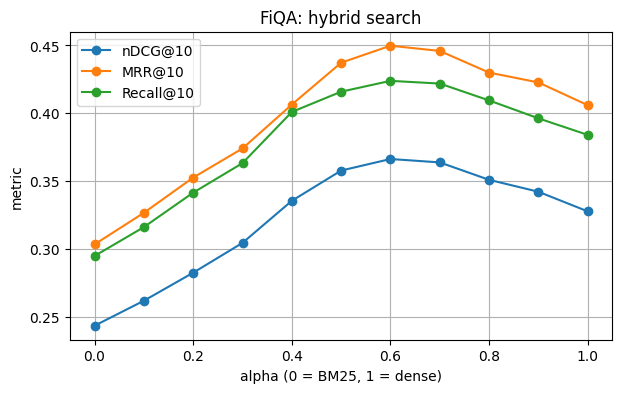

best alpha by nDCG@10: 0.6
indexing: 368s, mean latency: dense 120.2 ms / bm25 1177.7 ms, hnsw_ef=128

In [ ]:
results.plot(marker="o", figsize=(7, 4), grid=True)
plt.xlabel("alpha (0 = BM25, 1 = dense)")
plt.ylabel("metric")
plt.title("FiQA: hybrid search")
plt.show()

best = results['nDCG@10'].idxmax()
print(f'best alpha by nDCG@10: {best}')
print(f'indexing: {index_time:.0f}s, mean latency: dense {1000*np.mean(lat_dense):.1f} ms / bm25 {1000*np.mean(lat_sparse):.1f} ms, hnsw_ef={HNSW_EF}')

## Выводы

Оптимальное значение альфа для фьюжена равно 0.6, однако задержка при использование bm25 очень большая. Тюн параметров, типа HNSW может немного сгладить проблему без большого ущерба для релевантности выдачи, но в рабочих задачах стоит присмотреться, будет ли такая задержка для сервиса нормальной